<a href="https://colab.research.google.com/github/julianovale/geoestatistica/blob/main/001_geoestatistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
!pip install scikit-gstat gstools pykrige

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import skgstat as skg  # Biblioteca moderna para geoestatística e variogramas

# Configurações estéticas para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [17]:
import numpy as np
import pandas as pd

# URL raw do seu arquivo no GitHub
url = "https://raw.githubusercontent.com/julianovale/geoestatistica/refs/heads/main/datasets/walker.csv"

# Lendo o arquivo CSV diretamente para um DataFrame do Pandas
df_walker = pd.read_csv(url)

# Substituindo a convenção GSLIB (-999.0) por NaN na coluna U (e outras se houver)
df_walker["U"] = df_walker["U"].replace(-999.0, np.nan)

# Exibindo as primeiras linhas para verificar se carregou corretamente
print("--- Primeiras linhas do Walker Lake ---")
display(df_walker.head())

# Exibindo um resumo geral (contagem de nulos, tipos, etc.)
print("\n--- Informações do DataFrame ---")
df_walker.info()

--- Primeiras linhas do Walker Lake ---


,Id,X,Y,V,U,T
0,1.0,11.0,8.0,0.0,NaN,2.0
1,2.0,8.0,30.0,0.0,NaN,2.0
2,3.0,9.0,48.0,224.4,NaN,2.0
3,4.0,8.0,69.0,434.4,NaN,2.0
4,5.0,9.0,90.0,412.1,NaN,2.0



--- Informações do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470 entries, 0 to 469
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Id      470 non-null    float64
 1   X       470 non-null    float64
 2   Y       470 non-null    float64
 3   V       470 non-null    float64
 4   U       275 non-null    float64
 5   T       470 non-null    float64
dtypes: float64(6)
memory usage: 22.2 KB


--- Estatísticas Descritivas da Variável V ---
                 Estatística        Valor
      Número de Amostras (n)   470.000000
                       Média   435.298723
                     Mediana   424.000000
                      Mínimo     0.000000
                      Máximo  1528.100000
           Amplitude (Range)  1528.100000
        Variância (Amostral) 89929.395052
    Desvio Padrão (Amostral)   299.882302
             1º Quartil (Q1)   184.600000
             3º Quartil (Q3)   640.850000
Amplitude Interquartil (IQR)   456.250000
       Assimetria (Skewness)     0.460640
 Coeficiente de Variação (%)    68.891151


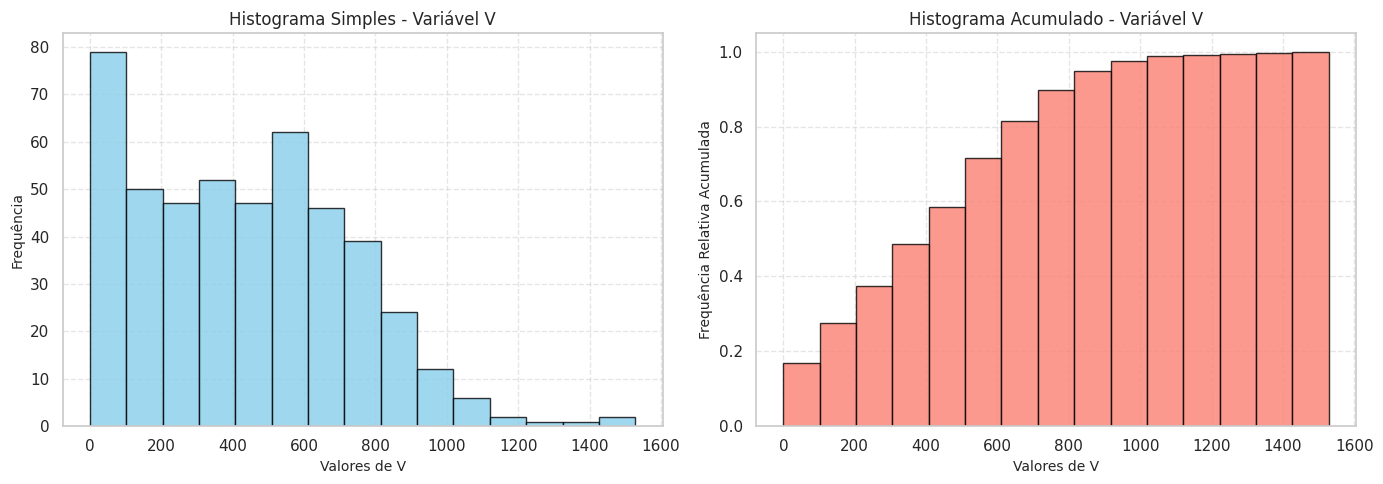

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Carregando os dados do Walker Lake
url = "https://raw.githubusercontent.com/julianovale/geoestatistica/refs/heads/main/datasets/walker.csv"
df_walker = pd.read_csv(url)

# Substituindo a convenção GSLIB (-999.0) por NaN na coluna V (e limpando)
df_walker["V"] = df_walker["V"].replace(-999.0, np.nan)
v_dados = df_walker["V"].dropna().values

# 2. Calculando as Estatísticas Descritivas completas para V
estatisticas_v = {
    "Estatística": [
        "Número de Amostras (n)",
        "Média",
        "Mediana",
        "Mínimo",
        "Máximo",
        "Amplitude (Range)",
        "Variância (Amostral)",
        "Desvio Padrão (Amostral)",
        "1º Quartil (Q1)",
        "3º Quartil (Q3)",
        "Amplitude Interquartil (IQR)",
        "Assimetria (Skewness)",
        "Coeficiente de Variação (%)",
    ],
    "Valor": [
        len(v_dados),
        np.mean(v_dados),
        np.median(v_dados),
        np.min(v_dados),
        np.max(v_dados),
        np.ptp(v_dados),
        np.var(v_dados, ddof=1),
        np.std(v_dados, ddof=1),
        np.percentile(v_dados, 25),
        np.percentile(v_dados, 75),
        np.percentile(v_dados, 75) - np.percentile(v_dados, 25),
        pd.Series(v_dados).skew(),
        (np.std(v_dados, ddof=1) / np.mean(v_dados)) * 100,
    ],
}

df_desc_v = pd.DataFrame(estatisticas_v)
print("--- Estatísticas Descritivas da Variável V ---")
print(df_desc_v.to_string(index=False))

# 3. Plotagem dos Histogramas (Simples e Acumulado)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma Simples (Frequência)
axes[0].hist(v_dados, bins=15, color="skyblue", edgecolor="black", alpha=0.8)
axes[0].set_title("Histograma Simples - Variável V")
axes[0].set_xlabel("Valores de V")
axes[0].set_ylabel("Frequência")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Histograma Acumulado (Empirical CDF)
axes[1].hist(
    v_dados,
    bins=15,
    color="salmon",
    edgecolor="black",
    alpha=0.8,
    cumulative=True,
    density=True,
)
axes[1].set_title("Histograma Acumulado - Variável V")
axes[1].set_xlabel("Valores de V")
axes[1].set_ylabel("Frequência Relativa Acumulada")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

--- Teste de Normalidade (Shapiro-Wilk) ---
Estatística W: 0.9629
Valor-p (p-value): 1.6575e-09
Resultado: Rejeitamos a hipótese nula (p < 0.05). Os dados NÃO seguem uma distribuição normal.


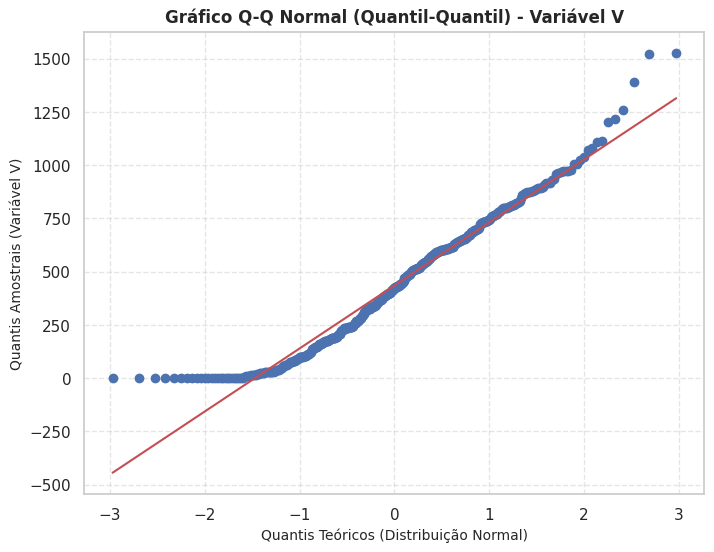

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Carregando e limpando os dados do Walker Lake
url = "https://raw.githubusercontent.com/julianovale/geoestatistica/refs/heads/main/datasets/walker.csv"
df_walker = pd.read_csv(url)
df_walker["V"] = df_walker["V"].replace(-999.0, np.nan)
v_dados = df_walker["V"].dropna().values

# 2. Teste de Normalidade (Shapiro-Wilk)
stat_shapiro, p_value = stats.shapiro(v_dados)

print("--- Teste de Normalidade (Shapiro-Wilk) ---")
print(f"Estatística W: {stat_shapiro:.4f}")
print(f"Valor-p (p-value): {p_value:.4e}")

if p_value < 0.05:
  print(
      "Resultado: Rejeitamos a hipótese nula (p < 0.05). Os dados NÃO seguem"
      " uma distribuição normal."
  )
else:
  print(
      "Resultado: Não rejeitamos a hipótese nula. Os dados não diferem"
      " significativamente de uma normal."
  )

# 3. Plotagem do Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(v_dados, dist="norm", plot=plt)
plt.title(
    "Gráfico Q-Q Normal (Quantil-Quantil) - Variável V",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Quantis Teóricos (Distribuição Normal)", fontsize=10)
plt.ylabel("Quantis Amostrais (Variável V)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

--- Teste de Normalidade após Transformação Lognormal ---
Estatística W: 0.7294
Valor-p (p-value): 6.3185e-27
Resultado: Rejeitamos a hipótese nula (p < 0.05). Mesmo após o log, os dados ainda apresentam desvios significativos da normalidade.


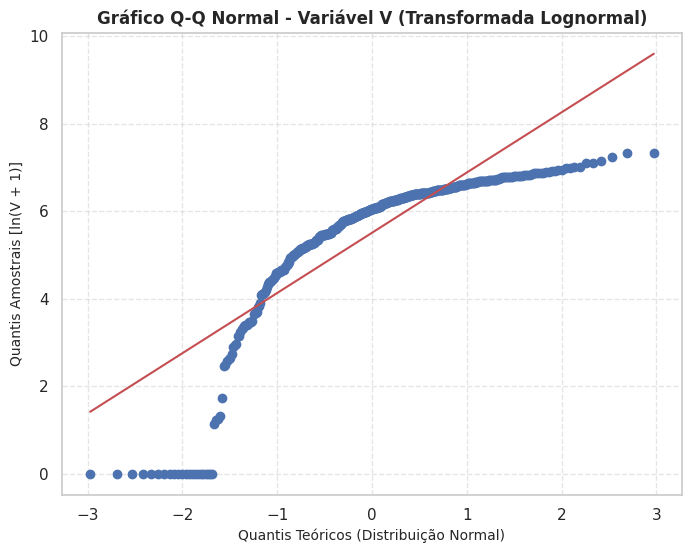

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Carregando e limpando os dados do Walker Lake
url = "https://raw.githubusercontent.com/julianovale/geoestatistica/refs/heads/main/datasets/walker.csv"
df_walker = pd.read_csv(url)
df_walker["V"] = df_walker["V"].replace(-999.0, np.nan)
v_dados = df_walker["V"].dropna().values

# 2. Aplicando a Transformação Lognormal (log1p para lidar com valores 0.0)
v_log = np.log1p(v_dados)

# 3. Teste de Normalidade (Shapiro-Wilk) nos dados transformados
stat_shapiro, p_value = stats.shapiro(v_log)

print("--- Teste de Normalidade após Transformação Lognormal ---")
print(f"Estatística W: {stat_shapiro:.4f}")
print(f"Valor-p (p-value): {p_value:.4e}")

if p_value < 0.05:
  print(
      "Resultado: Rejeitamos a hipótese nula (p < 0.05). Mesmo após o log,"
      " os dados ainda apresentam desvios significativos da normalidade."
  )
else:
  print(
      "Resultado: Não rejeitamos a hipótese nula. Os dados transformados"
      " passaram no teste de normalidade."
  )

# 4. Plotagem do Q-Q Plot dos dados transformados
plt.figure(figsize=(8, 6))
stats.probplot(v_log, dist="norm", plot=plt)
plt.title(
    "Gráfico Q-Q Normal - Variável V (Transformada Lognormal)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Quantis Teóricos (Distribuição Normal)", fontsize=10)
plt.ylabel("Quantis Amostrais [ln(V + 1)]", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [21]:
import pandas as pd

# Carregando os dados
url = "https://raw.githubusercontent.com/julianovale/geoestatistica/refs/heads/main/datasets/walker.csv"
df_walker = pd.read_csv(url)
df_walker["V"] = df_walker["V"].replace(-999.0, pd.NA)

# Estatísticas descritivas básicas prontas
print(df_walker["V"].describe())

# Para ver a Assimetria (Skewness) e a Variância que o describe() padrão não mostra direto:
print("Variância:", df_walker["V"].var())
print("Assimetria:", df_walker["V"].skew())

count     470.000000
mean      435.298723
std       299.882302
min         0.000000
25%       184.600000
50%       424.000000
75%       640.850000
max      1528.100000
Name: V, dtype: float64
Variância: 89929.39505167173
Assimetria: 0.46064029045869076


--- Estatísticas Descritivas da Variável V ---
count     470.000000
mean      435.298723
std       299.882302
min         0.000000
25%       184.600000
50%       424.000000
75%       640.850000
max      1528.100000
Name: V, dtype: float64

--- Tabela de Frequência ---


,Classe (Intervalo),Frequência Simples (fi),Frequência Relativa (%),Frequência Acumulada
0,0.00 |- 191.01,125,26.595745,125
1,191.01 |- 382.02,88,18.723404,213
2,382.02 |- 573.04,94,20.000000,307
3,573.04 |- 764.05,94,20.000000,401
4,764.05 |- 955.06,48,10.212766,449
5,955.06 |- 1146.07,15,3.191489,464
6,1146.07 |- 1337.09,3,0.638298,467
7,1337.09 |- 1528.10,3,0.638298,470


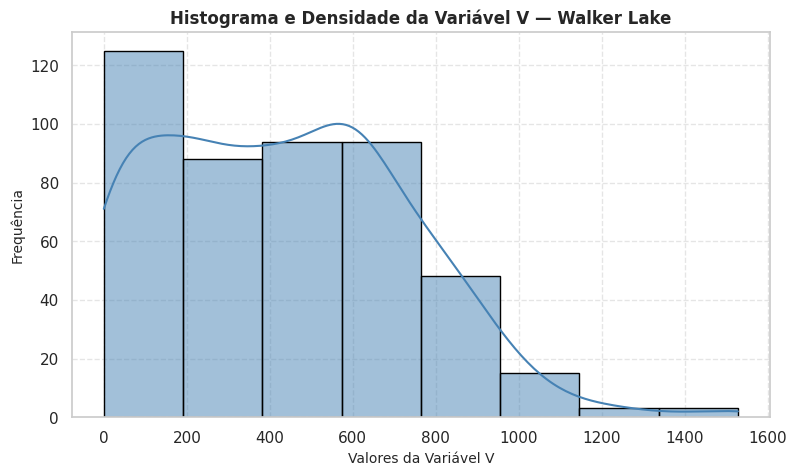

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Supondo que 'df_walker' já foi carregado anteriormente:
# df_walker['U'] = df_walker['U'].replace(-999.0, np.nan)

# 1. Estatísticas descritivas básicas da variável V (essenciais para a geoestatística)
print("--- Estatísticas Descritivas da Variável V ---")
print(df_walker["V"].describe())

# 2. Criação da Tabela de Frequência
# Definimos o número de classes (bins), por exemplo, 8 classes
num_bins = 8
counts, bin_edges = np.histogram(df_walker["V"].dropna(), bins=num_bins)

# Montando o DataFrame da Tabela de Frequência
tabela_freq = pd.DataFrame(
    {
        "Classe (Intervalo)": [
            f"{bin_edges[i]:.2f} |- {bin_edges[i+1]:.2f}"
            for i in range(len(bin_edges) - 1)
        ],
        "Frequência Simples (fi)": counts,
        "Frequência Relativa (%)": (counts / counts.sum()) * 100,
        "Frequência Acumulada": np.cumsum(counts),
    }
)

print("\n--- Tabela de Frequência ---")
display(tabela_freq)

# 3. Plotagem do Histograma e KDE (Curva de Densidade)
plt.figure(figsize=(9, 5))
sns.histplot(
    df_walker["V"].dropna(),
    bins=num_bins,
    kde=True,
    color="steelblue",
    edgecolor="black",
)

plt.title(
    "Histograma e Densidade da Variável V — Walker Lake",
    fontsize=12,
    weight="bold",
)
plt.xlabel("Valores da Variável V", fontsize=10)
plt.ylabel("Frequência", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

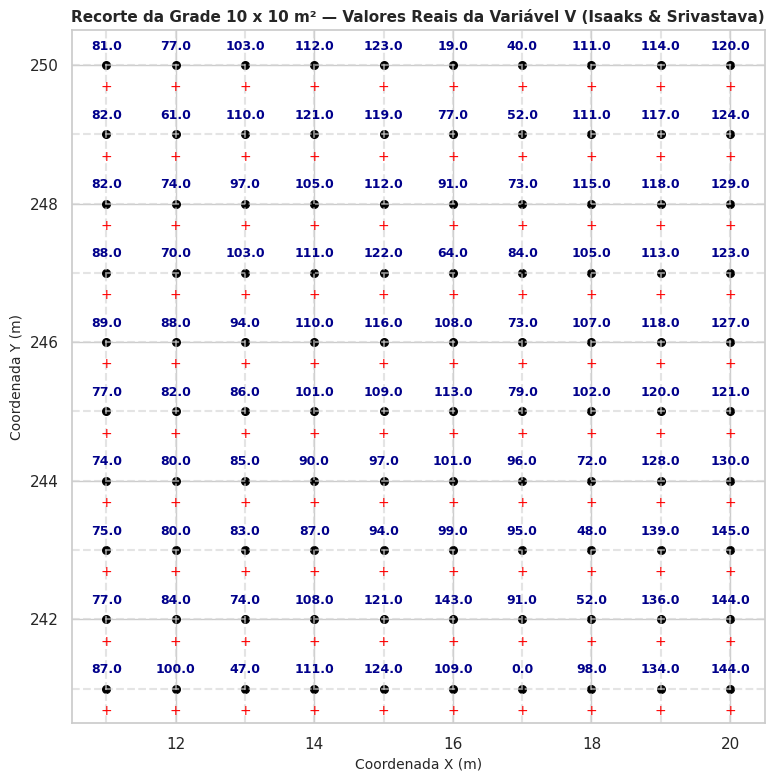

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Definindo as coordenadas da grade (X de 11 a 20, Y de 241 a 250)
x_vals = np.arange(11, 21)
y_vals = np.arange(241, 251)
xx, yy = np.meshgrid(x_vals, y_vals)

# 2. Matriz exata de 10x10 com os valores de V do livro (de Y=250 em cima até Y=241 embaixo)
# Cada linha corresponde a um Y (do 250 descendo até o 241) e colunas de X (11 até 20)
v_matrix = np.array(
    [
        [81, 77.0, 103.0, 112.0, 123.0, 19.0, 40.0, 111.0, 114.0, 120.0],  # Y = 250
        [82.0, 61.0, 110.0, 121.0, 119.0, 77.0, 52.0, 111.0, 117.0, 124.0],  # Y = 249
        [82.0, 74.0, 97.0, 105.0, 112.0, 91.0, 73.0, 115.0, 118.0, 129.0],  # Y = 248
        [88.0, 70.0, 103.0, 111.0, 122.0, 64.0, 84.0, 105.0, 113.0, 123.0],  # Y = 247
        [89.0, 88.0, 94.0, 110.0, 116.0, 108.0, 73.0, 107.0, 118.0, 127.0],  # Y = 246
        [77.0, 82.0, 86.0, 101.0, 109.0, 113.0, 79.0, 102.0, 120.0, 121.0],  # Y = 245
        [74.0, 80.0, 85.0, 90.0, 97.0, 101.0, 96.0, 72.0, 128.0, 130.0],  # Y = 244
        [75.0, 80.0, 83.0, 87.0, 94.0, 99.0, 95.0, 48.0, 139.0, 145.0],  # Y = 243
        [77.0, 84.0, 74.0, 108.0, 121.0, 143.0, 91.0, 52.0, 136.0, 144.0],  # Y = 242
        [87.0, 100.0, 47.0, 111.0, 124.0, 109.0, 0.0, 98.0, 134.0, 144.0],  # Y = 241
    ]
)

# Como a matriz numpy é indexada de cima para baixo (linha 0 = Y=250),
# invertemos a matriz verticalmente para bater com o eixo cartesiano Y crescendo para cima:
v_plot = np.flipud(v_matrix)

# 3. Plotagem da Grade 10x10
fig, ax = plt.subplots(figsize=(9, 9))

ax.set_xlim(10.5, 20.5)
ax.set_ylim(240.5, 250.5)

# Linhas de grade
for x in x_vals:
    ax.axvline(x, color="lightgray", linestyle="--", alpha=0.6)
for y in y_vals:
    ax.axhline(y, color="lightgray", linestyle="--", alpha=0.6)

# Pontos e Rótulos
ax.scatter(xx, yy, color="black", s=30)

for i in range(v_matrix.shape[0]):
    for j in range(v_matrix.shape[1]):
        val = v_matrix[i, j]
        x_coord = x_vals[j]
        y_coord = y_vals[9 - i]  # Invertendo índice para corresponder ao Y correto

        # Exibindo o valor de V em cima e o símbolo '+' embaixo
        ax.text(
            x_coord,
            y_coord + 0.18,
            f"{val:.1f}" if isinstance(val, float) else str(val),
            fontsize=9,
            ha="center",
            va="bottom",
            color="darkblue",
            weight="bold",
        )
        ax.text(
            x_coord,
            y_coord - 0.22,
            "+",
            fontsize=10,
            ha="center",
            va="top",
            color="red",
        )

ax.set_title(
    "Recorte da Grade 10 x 10 m² — Valores Reais da Variável V (Isaaks & Srivastava)",
    fontsize=11,
    weight="bold",
)
ax.set_xlabel("Coordenada X (m)")
ax.set_ylabel("Coordenada Y (m)")
plt.gca().set_aspect("equal", adjustable="box")
plt.show()

--- Tabela de Frequência (Classes de 10 em 10) ---


,Classe (Intervalo),Frequência Simples (fi),Frequência Relativa (%),Frequência Acumulada
0,0 |- 10,1,1.0,1
1,10 |- 20,1,1.0,2
2,20 |- 30,0,0.0,2
3,30 |- 40,0,0.0,2
4,40 |- 50,3,3.0,5
5,50 |- 60,2,2.0,7
6,60 |- 70,2,2.0,9
7,70 |- 80,13,13.0,22
8,80 |- 90,16,16.0,38
9,90 |- 100,11,11.0,49


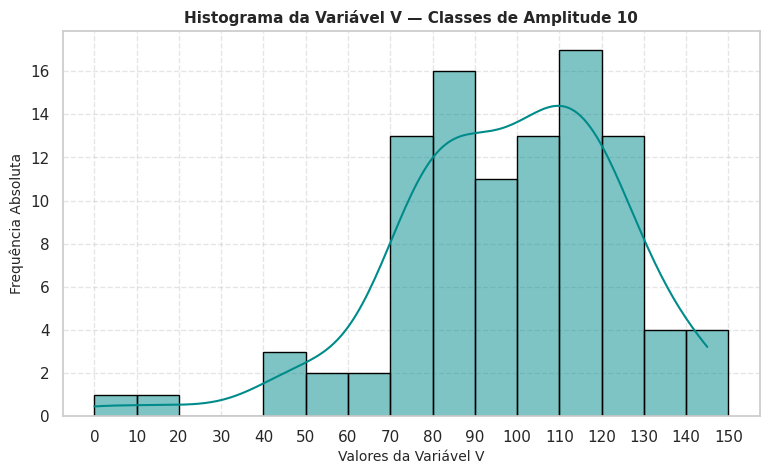

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Transformando a matriz 10x10 em um vetor unidimensional (100 elementos)
v_values = v_matrix.flatten()

# 1. Definindo os limites das classes de 10 em 10
# Descobrimos o valor mínimo e máximo para abranger todos os dados
v_min = np.floor(v_values.min() / 10) * 10  # Arredonda para baixo (ex: 0.0)
v_max = (
    np.ceil(v_values.max() / 10) * 10
)  # Arredonda para cima (ex: 150.0)

# Cria um array de 10 em 10: [0, 10, 20, 30, ..., 150]
bin_edges = np.arange(v_min, v_max + 10, 10)

# 2. Criação da Tabela de Frequência com os bins de tamanho 10
counts, _ = np.histogram(v_values, bins=bin_edges)

tabela_freq = pd.DataFrame(
    {
        "Classe (Intervalo)": [
            f"{bin_edges[i]:.0f} |- {bin_edges[i+1]:.0f}"
            for i in range(len(bin_edges) - 1)
        ],
        "Frequência Simples (fi)": counts,
        "Frequência Relativa (%)": (counts / counts.sum()) * 100,
        "Frequência Acumulada": np.cumsum(counts),
    }
)

print("--- Tabela de Frequência (Classes de 10 em 10) ---")
display(tabela_freq)

# 3. Plotagem do Histograma usando exatamente os mesmos limites (bins)
plt.figure(figsize=(9, 5))
sns.histplot(
    v_values, bins=bin_edges, kde=True, color="darkcyan", edgecolor="black"
)

plt.title(
    "Histograma da Variável V — Classes de Amplitude 10",
    fontsize=11,
    weight="bold",
)
plt.xlabel("Valores da Variável V", fontsize=10)
plt.ylabel("Frequência Absoluta", fontsize=10)

# Ajusta os ticks do eixo X para mostrar cada marcação de 10 em 10
plt.xticks(bin_edges)

plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

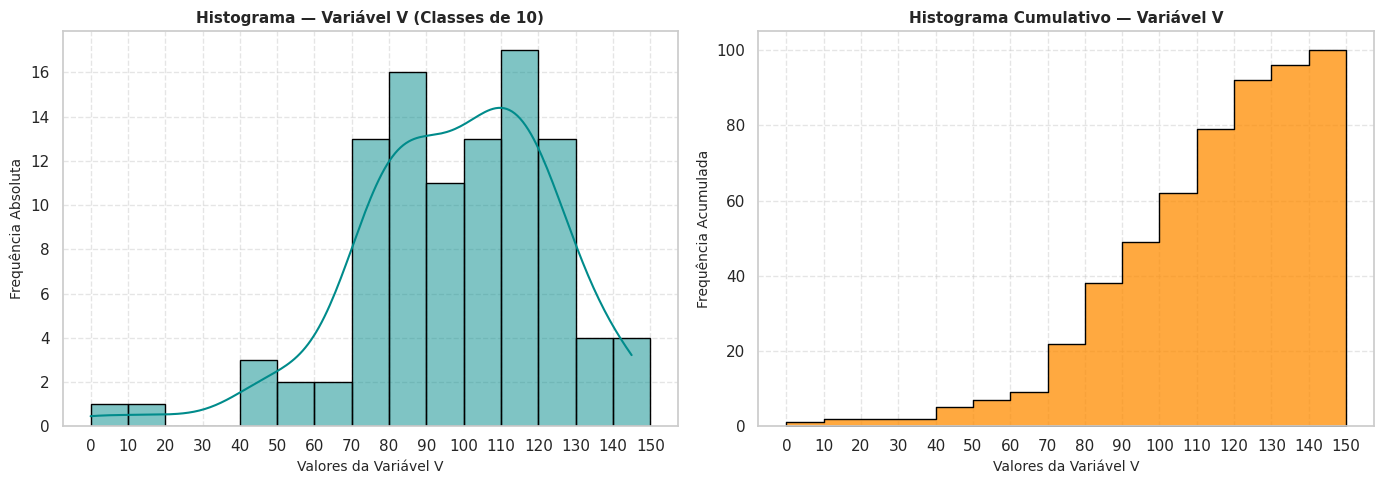

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Transformando a matriz 10x10 em um vetor unidimensional (100 elementos)
v_values = v_matrix.flatten()

# 1. Definindo os limites das classes de 10 em 10
v_min = np.floor(v_values.min() / 10) * 10
v_max = np.ceil(v_values.max() / 10) * 10
bin_edges = np.arange(v_min, v_max + 10, 10)

# 2. Plotagem: Vamos criar uma figura com 2 subplots (um para o histograma normal e outro para o cumulativo)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Histograma de Frequência Simples ---
sns.histplot(
    v_values,
    bins=bin_edges,
    kde=True,
    color="darkcyan",
    edgecolor="black",
    ax=ax1,
)
ax1.set_title(
    "Histograma — Variável V (Classes de 10)", fontsize=11, weight="bold"
)
ax1.set_xlabel("Valores da Variável V", fontsize=10)
ax1.set_ylabel("Frequência Absoluta", fontsize=10)
ax1.set_xticks(bin_edges)
ax1.grid(True, linestyle="--", alpha=0.5)

# --- Histograma / Gráfico Cumulativo ---
sns.histplot(
    v_values,
    bins=bin_edges,
    cumulative=True,
    stat="count",
    color="darkorange",
    edgecolor="black",
    element="step",
    ax=ax2,
)
ax2.set_title(
    "Histograma Cumulativo — Variável V", fontsize=11, weight="bold"
)
ax2.set_xlabel("Valores da Variável V", fontsize=10)
ax2.set_ylabel("Frequência Acumulada", fontsize=10)
ax2.set_xticks(bin_edges)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

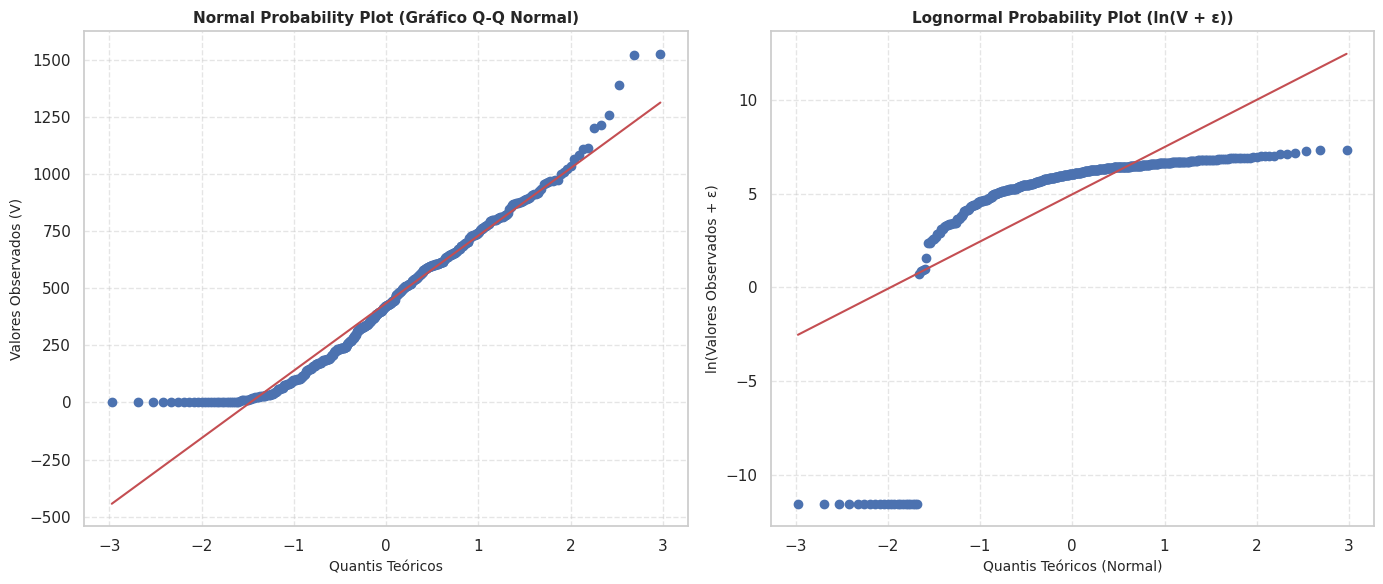

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Obtendo os valores válidos da variável V
v_values = df_walker["V"].dropna().values

# Configurando a figura com 2 subplots (Normal e Lognormal corrigido)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 1. Normal Probability Plot (Q-Q Plot Normal)
stats.probplot(v_values, dist="norm", plot=ax1)
ax1.set_title(
    "Normal Probability Plot (Gráfico Q-Q Normal)",
    fontsize=11,
    weight="bold",
)
ax1.set_xlabel("Quantis Teóricos", fontsize=10)
ax1.set_ylabel("Valores Observados (V)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Lognormal Probability Plot (Tratando os zeros)
# Como existem zeros, adicionamos um pequeno valor constante (epsilon ou offset)
# se necessário, ou aplicamos o log direto nos valores estritamente positivos,
# mas a forma mais padrão no SciPy para q-q plot lognormal com zeros é usar
# uma leve translação ou filtrar, ou usar log nativo:
epsilon = 1e-5  # valor infinitesimal para evitar log(0)
v_log_adjusted = np.log(v_values + epsilon)

# Plotando comparando o log dos dados contra uma distribuição normal teórica
stats.probplot(v_log_adjusted, dist="norm", plot=ax2)
ax2.set_title(
    "Lognormal Probability Plot (ln(V + ε))", fontsize=11, weight="bold"
)
ax2.set_xlabel("Quantis Teóricos (Normal)", fontsize=10)
ax2.set_ylabel("ln(Valores Observados + ε)", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import scipy.stats as stats

# Removendo NaNs e obtendo os valores
v_values = df_walker["V"].dropna().values

# Teste de Shapiro-Wilk para os dados originais
shapiro_orig = stats.shapiro(v_values)
print(
    f"Shapiro-Wilk (Originais) - Estatística: {shapiro_orig.statistic:.4f}, p-valor: {shapiro_orig.pvalue:.4e}"
)

# Teste de Shapiro-Wilk para o log dos dados (com epsilon para evitar zero)
shapiro_log = stats.shapiro(np.log(v_values + 1e-5))
print(
    f"Shapiro-Wilk (Log)      - Estatística: {shapiro_log.statistic:.4f}, p-valor: {shapiro_log.pvalue:.4e}"
)

Shapiro-Wilk (Originais) - Estatística: 0.9629, p-valor: 1.6575e-09
Shapiro-Wilk (Log)      - Estatística: 0.4341, p-valor: 7.0778e-36


In [28]:
import numpy as np
import pandas as pd

# Exemplo de np.array
dados = v_matrix.flatten()

# Calculando as estatísticas descritivas
estatisticas = {
    "Estatística": [
        "Número de Amostras (n)",
        "Média",
        "Mediana",
        "Mínimo",
        "Máximo",
        "Amplitude (Range)",
        "Variância (Amostral)",
        "Desvio Padrão (Amostral)",
        "1º Quartil (Q1)",
        "3º Quartil (Q3)",
        "Amplitude Interquartil (IQR)",
        "Assimetria (Skewness)",
        "Coeficiente de Variação (%)"
    ],
    "Valor": [
        len(dados),
        np.mean(dados),
        np.median(dados),
        np.min(dados),
        np.max(dados),
        np.ptp(dados), # Peak-to-peak (Max - Min)
        np.var(dados, ddof=1), # Variância amostral (n-1)
        np.std(dados, ddof=1),  # Desvio padrão amostral (n-1)
        np.percentile(dados, 25),
        np.percentile(dados, 75),
        np.percentile(dados, 75) - np.percentile(dados, 25),
        pd.Series(dados).skew(), # Assimetria
        (np.std(dados, ddof=1) / np.mean(dados)) * 100  # Coeficiente de Variação
    ]
}

# Criando o DataFrame (quadro)
df_descritiva = pd.DataFrame(estatisticas)

# Exibindo o quadro formatado
print(df_descritiva.to_string(index=False))

                 Estatística      Valor
      Número de Amostras (n) 100.000000
                       Média  97.550000
                     Mediana 100.500000
                      Mínimo   0.000000
                      Máximo 145.000000
           Amplitude (Range) 145.000000
        Variância (Amostral) 695.340909
    Desvio Padrão (Amostral)  26.369318
             1º Quartil (Q1)  81.750000
             3º Quartil (Q3) 116.250000
Amplitude Interquartil (IQR)  34.500000
       Assimetria (Skewness)  -0.790067
 Coeficiente de Variação (%)  27.031592
